In [393]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import matplotlib.lines as mlines

# Qualitative comparison of performances based on spatial resolution

## Aim of Tutorial

The aim of this tutorial is to further dive into the dispersive and diffusive properties of the tracer advection schemes. Here we choose to transport sinusoidal signals at different frequencies to compare the performances of the different schemes based on the spatial resolution of the signal.


## Running the simulation

__To make the recquired changes and run the simulation you can execute the cells below__

In [405]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00



cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_gauss_ubs.*
rm CANAL_gauss_fct2.*
rm CANAL_gauss_fct4.*

chmod -R a+x /"$DIR"/demo_gauss/

bash /"$DIR"/demo_gauss/gauss_istate.sh "$DIR"
bash /"$DIR"/demo_gauss/gauss_cfg.sh "$DIR"
bash /"$DIR"/demo_gauss/lambda_run.sh "$DIR" "25 50 100 200"
    

106a107
>             pts(:,:,jk,jp_sal) = 30._wp+5._wp*EXP( -0.5_wp *glamt(:,:)**2 / rn_lambda**2 )
Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
Compilation form : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

Process is interrupted.


## Comparative plots

### Salinity variance for a sinusoidal signal

In [239]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''


In [346]:
w_list = [5, 3, 1]
scheme_list = ['cen2', 'cen4', 'ubs', 'fct2', 'fct4']
colors = {'cen2' : 'red', 'cen4' : 'orange', 'ubs' : 'blue', 'fct2' : 'green', 'fct4' : 'lightgreen'}

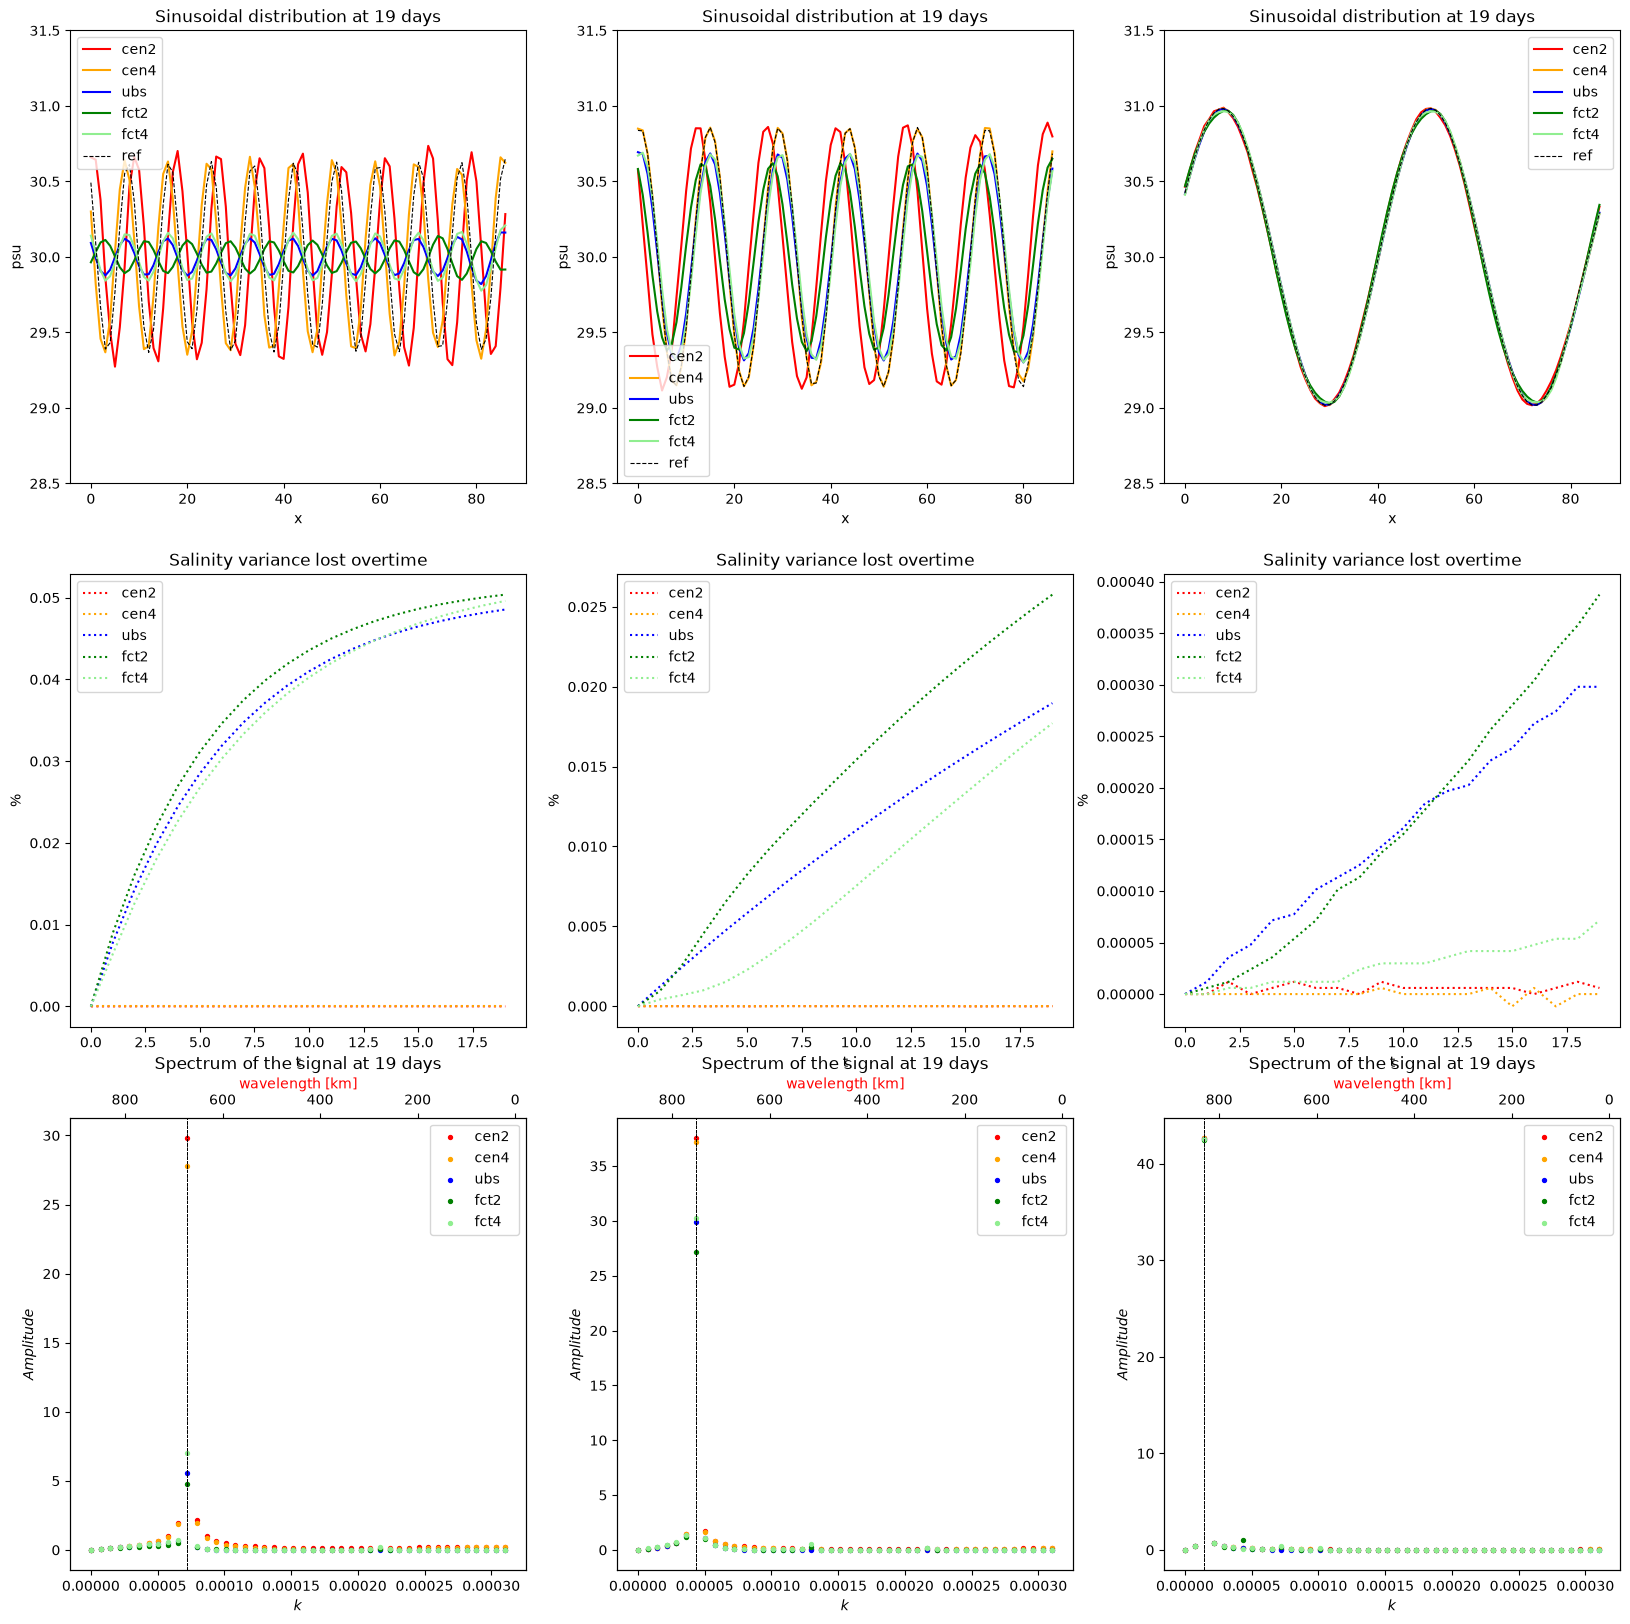

In [472]:

v= 0.5
dx = 10000
dt = 24*3600
ref = []
t = 19
fig_salt2c, axes_salt2c = plt.subplots(3, len(w_list), figsize=(20,20)) 


for i, l in enumerate(w_list):
        for scheme in scheme_list :
            dataset = xr.open_dataset(rep+'CANAL_sin_'+scheme+str(l)+'_all_grid.nc', decode_times=False)
            s2c = dataset['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
            s2c = np.array(s2c)
            data = (1-s2c/s2c[0])*100
            time = np.arange(s2c.shape[0])
            axes_salt2c[1][i].plot(time, data, ':', color = colors[scheme], label = scheme)#plotting the ratio of the lost variance
            axes_salt2c[1][i].set_title(f"Salinity variance lost overtime")
            axes_salt2c[1][i].set_xlabel('t'),
            axes_salt2c[1][i].set_ylabel('%')
            sin = dataset['soce'].isel(time_counter=t, y_grid_T = 50, deptht=0)
            x = np.arange(sin.shape[0])
            axes_salt2c[0][i].plot(x, sin, color = colors[scheme], label = scheme)
            F = np.fft.rfft(sin - sin.mean())
            k = 2*np.pi*np.fft.rfftfreq(sin.shape[0], dx)
            axes_salt2c[2][i].scatter(k, np.abs(F), s=8, color = colors[scheme], label=f'{scheme} ')
            axes_salt2c[2][i].axvline(l*2*2*np.pi/870000, color='k', ls='--', lw=0.6)
            axes_salt2c[2][i].set_xlabel(r'$k$')
            axes_salt2c[2][i].set_ylabel(r'$Amplitude$')
            axes_salt2c[2][i].set_title(f'Spectrum of the signal at {t} days')
            axes_salt2c[2][i].legend()
        sin0 = dataset['soce'].isel(time_counter=0, y_grid_T = 50, deptht=0)
        ref = np.roll(sin0, shift=v*dt*(t)/dx)
        axes_salt2c[0][i].plot(x, ref, '--',  color ='k', label = 'ref', lw=0.8)
        axes_salt2c[0][i].set_title(f"Sinusoidal distribution at {t} days")
        axes_salt2c[0][i].set_ylim(28.5, 31.5)
        axes_salt2c[0][i].set_xlabel('x')
        axes_salt2c[0][i].set_ylabel('psu')
        axes_salt2c[0][i].legend()
        axes_salt2c[1][i].legend()
        axes_lambda = axes_salt2c[2][i].twiny()
        wavelength = 2*np.pi/k[1:]/1000
        axes_lambda.plot(wavelength, np.abs(F[1:]), alpha = 0)
        plt.gca().invert_xaxis()
        axes_lambda.set_xlabel('wavelength [km]', color='r')


### Phase speed and dampening factor 

##### To see more explanations on [phase speed and dampening effect](cp_theory.md)

/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_46637/3374117504.py:13: RuntimeWarning: divide by zero encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt with numpy convention
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_46637/3374117504.py:13: RuntimeWarning: invalid value encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt with numpy convention
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_46637/3374117504.py:17: RuntimeWarning: divide by zero encountered in divide
  A = np.abs(F[1:]/F[:-1])
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_46637/3374117504.py:17: RuntimeWarning: invalid value encountered in divide
  A = np.abs(F[1:]/F[:-1])
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_46637/3374117504.py:20: RuntimeWarning: invalid value encountered in multiply
  D[i] = np.sum(w[:,i]*A[:,i]) / np.sum(w)


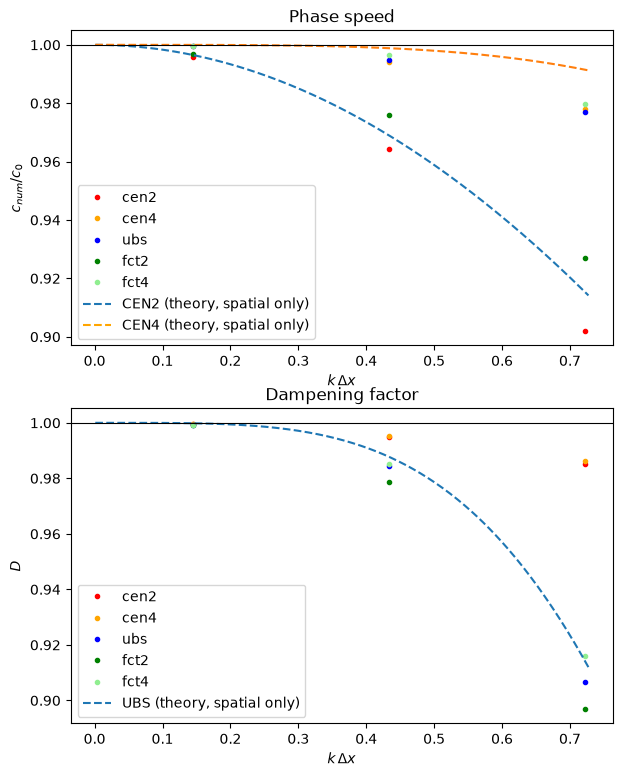

In [473]:
dx = 10000 #[m]
dt = 24*3600 #[s]
c0 = 0.5 #[m/s]
theta_max = min(np.pi, np.pi*dx/(c0*dt)) #maximum value of theta to avoid spectral aliasing
k_max = theta_max/dx

def phase_speed(f, dx, dt):
    """f[t, x] -> k, c(k) mesuré par la rotation de phase entre pas de temps."""
    F = np.fft.rfft(f - f.mean(axis=1, keepdims=True), axis=1)
    k = 2*np.pi*np.fft.rfftfreq(f.shape[1], dx)
    F=F[:,1:]
    k=k[1:]
    dphi = np.angle(F[1:] / F[:-1])          # = -ω dt with numpy convention 
    w = np.abs(F[1:]*F[:-1])               # amplitude weighting
    c = np.full(k.shape, np.nan)
    D = np.full(k.shape, np.nan)
    A = np.abs(F[1:]/F[:-1]) 
    for i in range(1, len(k)):
        c[i] = -np.sum(w[:,i]*dphi[:, i]) / (np.sum(w)*k[i] * dt)   
        D[i] = np.sum(w[:,i]*A[:,i]) / np.sum(w)
    return k, c, D


theta = np.linspace(1e-3, theta_max, 400)                       # θ = k·dx
theory = { #theoretical expression of c_p = ω/k for CEN2 and CEN4 for spatial discretisation only
    'cen2': np.sin(theta) / theta, 
    'cen4': (4/3*np.sin(theta) - 1/6*np.sin(2*theta)) / theta,
}
theory_D = { #theoretical expression of c_p = ω/k for CEN2 and CEN4 for spatial discretisation only
    'ubs': np.exp(-c0*dt/(3*dx)*(1-np.cos(theta))**2), 
}

fig, ax = plt.subplots(2, 1, figsize=(7, 9))
for scheme in scheme_list :
    for i, l in enumerate(w_list):
            dataset = xr.open_dataset(rep+'CANAL_sin_'+scheme+str(l)+'_all_grid.nc', decode_times=False)
            f = dataset['soce'].isel(y_grid_T=50, deptht=0).values
            k, c, D = phase_speed(f, dx, dt)
            mask2 = c/c0>0.01
            k = k[mask2]
            c = c[mask2]
            ax[0].plot(k*dx, c / c0, '.', color=colors[scheme], label = f"{scheme}")
            D = D[mask2]
            ax[1].plot(k*dx, D, '.', color=colors[scheme])
for name, c_th in theory.items():
    ax[0].plot(theta, c_th, '--', label=f'{name} (theory, spatial only)')
ax[0].set_xlabel(r'$k\,\Delta x$')
ax[0].set_ylabel(r'$c_{num}/c_0$')
ax[0].set_title(r'Phase speed')
ax[0].axhline(1, color='k', lw=0.8)

ax[0].legend(handles=[mlines.Line2D([],[],color=colors[n],ls='None',marker='.',label = f"{n}",) for n, scheme in schemes_sin.items()]+[ mlines.Line2D([],[],ls='--',label = f"CEN2 (theory, spatial only)"), mlines.Line2D([],[],ls='--',color = 'orange', label = f"CEN4 (theory, spatial only)"),])



for name, c_th in theory_D.items():
    ax[1].plot(theta, c_th, '--', label=f'{name} (theory, spatial only)')
    
ax[1].axhline(1, color='k', lw=0.8)
ax[1].set_xlabel(r'$k\,\Delta x$')
ax[1].set_ylabel(r'$D$')
ax[1].set_title(r'Dampening factor')
ax[1].legend(handles=[mlines.Line2D([],[],color=colors[n],ls='None',marker='.',label = f"{n}",) for n, scheme in schemes_sin.items()]+[ mlines.Line2D([],[],ls='--',label = f"UBS (theory, spatial only)")])

plt.show()

### Salinity 

In [474]:
cen2 = xr.open_dataset(rep+'CANAL_sin_cen23_all_grid.nc', decode_times=False)
cen4 = xr.open_dataset(rep+'CANAL_sin_cen43_all_grid.nc', decode_times=False)
ubs = xr.open_dataset(rep+'CANAL_sin_ubs3_all_grid.nc', decode_times=False)
fct2 = xr.open_dataset(rep+'CANAL_sin_fct23_all_grid.nc', decode_times=False)
fct4 = xr.open_dataset(rep+'CANAL_sin_fct43_all_grid.nc', decode_times=False)

In [509]:
schemes = { 'cen2' : cen2, 'cen4': cen4, 'fct2' : fct2, 'fct4' : fct4,  'ubs': ubs}
colors = {'cen2': 'red', 'cen4': 'orange',  'fct2' : 'green', 'fct4' : 'lightgreen', 'ubs': 'blue'}

soce = {n: ds['soce'].isel(y_grid_T=50, deptht=0).values
          for n, ds in schemes.items()}


In [510]:
v= 0.5
dx = 10000
domx = 864000
ref = []
gauss_0 = [30 +np.sin(3*2*2*np.pi*i*dx/domx) for i in range(int(domx/dx))]



for t in range (80):
    ref.append(np.roll(gauss_0, shift=v*86400*(t+0.5)/dx))
    


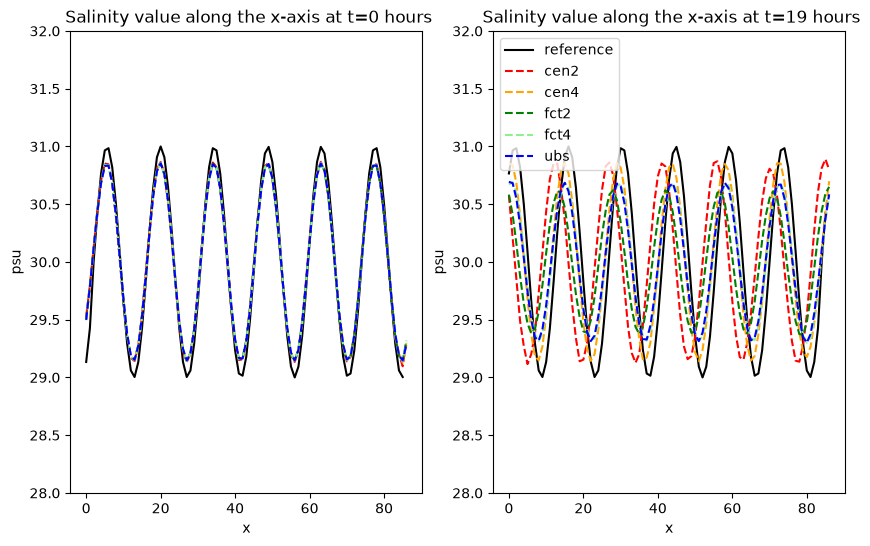

In [511]:
t_list = [0, 19]

fig, ax = plt.subplots(1, len(t_list), figsize=(10,6))

for i,t in enumerate(t_list):
    ax[i].plot(np.arange(len(ref[0])), ref[t], color ='black', label ='reference')
    for n, ds in soce.items() :
        ax[i].plot(np.arange(ds.shape[1]), ds[t], '--', color = colors[n], label = n)
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('psu')
    ax[i].set_ylim(28,32)
    ax[i].set_title(f' Salinity value along the x-axis at t={t} hours')


plt.legend(loc='upper left')

In [488]:
cen2.close()
ubs.close()
fct2.close()

In [489]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

bash /"$DIR"/demo_gauss/end_gauss.sh "$DIR"

111d110
<             !pts(:,:,jk,jp_sal) = 30._wp+5._wp*EXP( -0.5_wp *glamt(:,:)**2 / rn_lambda**2 )
Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
Compiling
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

Process is interrupted.
